In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp

In [3]:
numQubits = 10
numCircuits = 50
maxPeriods = 50

rotationRange = np.pi / 4
interactionAngle = np.pi / 4

randomSeed = 42
rng = np.random.default_rng(randomSeed)

In [4]:
def createFloquetPeriod(numQubits, rxAngles, ryAngles, interactionAngle):
    circuit = QuantumCircuit(numQubits)

    # Step 1: Apply Rx rotations to every qubit
    for qubit in range(numQubits):
        circuit.rx(rxAngles[qubit], qubit)

    # Step 2: Apply RZZ gates to even pairs
    for qubit in range(0, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Step 3: Apply RZZ gates to odd pairs
    for qubit in range(1, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Step 4: Apply Ry rotations to every qubit
    for qubit in range(numQubits):
        circuit.ry(ryAngles[qubit], qubit)

    # Step 5: Apply RZZ gates to even pairs
    for qubit in range(0, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Step 6: Apply RZZ gates to odd pairs
    for qubit in range(1, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    return circuit

In [5]:
rxAngles = rng.uniform(-rotationRange, rotationRange, numQubits)
ryAngles = rng.uniform(-rotationRange, rotationRange, numQubits)

floquetPeriod = createFloquetPeriod(
    numQubits,
    rxAngles,
    ryAngles,
    interactionAngle
)

print(floquetPeriod)

      ┌─────────────┐           ┌──────────────┐                           »
q_0: ─┤ Rx(0.43033) ├──■────────┤ Ry(-0.20295) ├──────────────────■────────»
      ├─────────────┴┐ │ZZ(π/4) └──────────────┘ ┌─────────────┐  │ZZ(π/4) »
q_1: ─┤ Rx(-0.09601) ├─■────────────■────────────┤ Ry(0.67036) ├──■────────»
      ├─────────────┬┘              │ZZ(π/4)     ├─────────────┤           »
q_2: ─┤ Rx(0.56328) ├──■────────────■────────────┤ Ry(0.22598) ├──■────────»
      ├─────────────┤  │ZZ(π/4)                  ├─────────────┤  │ZZ(π/4) »
q_3: ─┤ Rx(0.31002) ├──■────────────■────────────┤ Ry(0.50699) ├──■────────»
      ├─────────────┴┐              │ZZ(π/4)    ┌┴─────────────┴┐          »
q_4: ─┤ Rx(-0.63746) ├─■────────────■───────────┤ Ry(-0.088885) ├─■────────»
      ├─────────────┬┘ │ZZ(π/4)                 └┬──────────────┤ │ZZ(π/4) »
q_5: ─┤ Rx(0.74711) ├──■────────────■────────────┤ Ry(-0.42845) ├─■────────»
      └┬────────────┤               │ZZ(π/4)     ├──────────────┤          »

In [6]:
def createFloquetCircuit(floquetPeriod, numPeriods):
    numQubits = floquetPeriod.num_qubits

    circuit = QuantumCircuit(numQubits)

    for period in range(numPeriods):
        circuit.compose(floquetPeriod, inplace=True)

    return circuit

In [7]:
numPeriods = 3

floquetCircuit = createFloquetCircuit(floquetPeriod, numPeriods)

print("Number of Floquet periods:", numPeriods)
print("Total gates:", floquetCircuit.size())
print("Circuit depth:", floquetCircuit.depth())

Number of Floquet periods: 3
Total gates: 114
Circuit depth: 18


In [8]:
# Create a Pauli-Z operator acting on qubit 0
pauliZ = SparsePauliOp("I" * (numQubits - 1) + "Z")

print(pauliZ)

SparsePauliOp(['IIIIIIIIIZ'],
              coeffs=[1.+0.j])


In [9]:
# Simulate the quantum state after 3 Floquet periods
state = Statevector.from_instruction(floquetCircuit)

# Calculate the expectation value of Pauli-Z on qubit 0
expectationValue = state.expectation_value(pauliZ).real

print("Pauli-Z expectation value:", expectationValue)

Pauli-Z expectation value: 0.8831424868057978


In [10]:
periods = list(range(maxPeriods + 1))
expectationValues = []

for period in periods:
    # Create a circuit with the specified number of periods
    circuit = createFloquetCircuit(floquetPeriod, period)

    # Simulate the resulting quantum state
    state = Statevector.from_instruction(circuit)

    # Calculate the Pauli-Z expectation value
    value = state.expectation_value(pauliZ).real

    # Store the result
    expectationValues.append(value)

print("Number of expectation values:", len(expectationValues))
print("Initial expectation value:", expectationValues[0])
print("Expectation value after 3 periods:", expectationValues[3])
print("Expectation value after 50 periods:", expectationValues[50])

Number of expectation values: 51
Initial expectation value: 1.0
Expectation value after 3 periods: 0.8831424868057978
Expectation value after 50 periods: 0.907360599069723


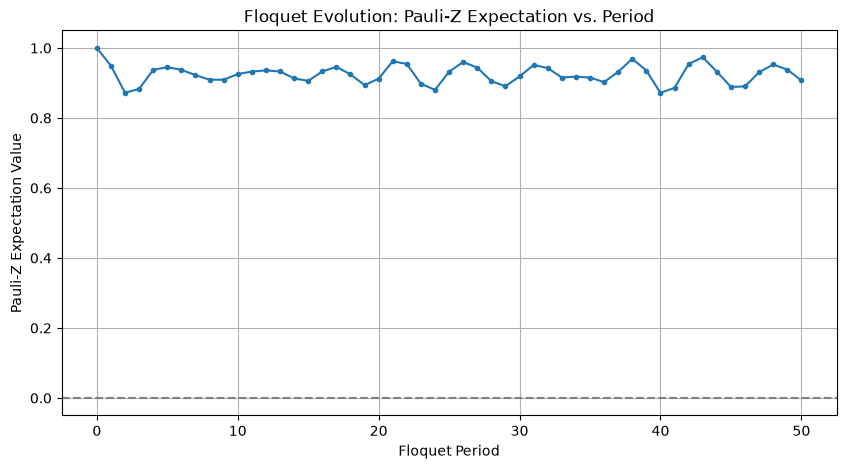

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(periods, expectationValues, marker="o", markersize=3)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Floquet Period")
plt.ylabel("Pauli-Z Expectation Value")
plt.title("Floquet Evolution: Pauli-Z Expectation vs. Period")

plt.grid(True)
plt.show()

In [12]:
# Store expectation values for all randomized circuits
allExpectationValues = []

for circuitIndex in range(numCircuits):

    # Generate new random angles for this circuit
    rxAngles = rng.uniform(-rotationRange, rotationRange, numQubits)
    ryAngles = rng.uniform(-rotationRange, rotationRange, numQubits)

    # Create one fixed Floquet period
    floquetPeriod = createFloquetPeriod(
        numQubits,
        rxAngles,
        ryAngles,
        interactionAngle
    )

    # Store expectation values for this circuit
    circuitValues = []

    for period in periods:

        # Repeat the same Floquet period
        circuit = createFloquetCircuit(floquetPeriod, period)

        # Simulate the quantum state
        state = Statevector.from_instruction(circuit)

        # Calculate Pauli-Z expectation value
        value = state.expectation_value(pauliZ).real

        circuitValues.append(value)

    allExpectationValues.append(circuitValues)

print("Number of randomized circuits:", len(allExpectationValues))
print("Expectation values per circuit:", len(allExpectationValues[0]))

Number of randomized circuits: 50
Expectation values per circuit: 51


In [13]:
# Convert the list into a NumPy array
allExpectationValues = np.array(allExpectationValues)

# Average across the 50 randomized circuits
averageExpectationValues = np.mean(allExpectationValues, axis=0)

print("Number of averaged values:", len(averageExpectationValues))
print("Initial average:", averageExpectationValues[0])
print("Average after 50 periods:", averageExpectationValues[50])

Number of averaged values: 51
Initial average: 1.0
Average after 50 periods: 0.8120783214158638


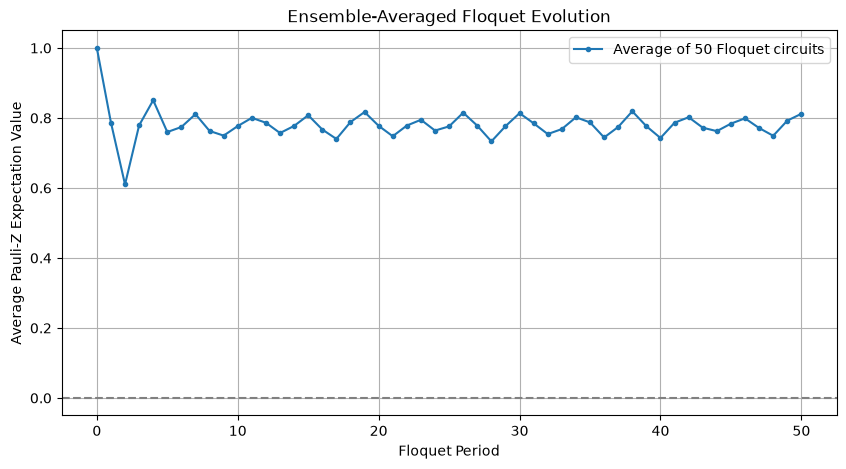

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    periods,
    averageExpectationValues,
    marker="o",
    markersize=3,
    label="Average of 50 Floquet circuits"
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Floquet Period")
plt.ylabel("Average Pauli-Z Expectation Value")
plt.title("Ensemble-Averaged Floquet Evolution")

plt.legend()
plt.grid(True)
plt.show()